# DEV · CardioRitmo: tamizaje de latidos
**Equipo:** León Franco Fernando, Mendoza Rodriguez Rodrigo, Muñoz Delgado Gael Arturo
**Datos:** ECG5000 del archivo UCR, 4,998 latidos de 140 puntos de un solo paciente (BIDMC, PhysioNet)
**Entorno:** Google Colab con GPU T4

**Lo que pide el cliente, en la prueba y con umbral de 0.5:**

| Especificación | Mínimo |
|---|---|
| Sensibilidad: de cada 100 latidos anormales, cuántos marca | 95 % |
| Especificidad: de cada 100 latidos normales, cuántos no marca | 95 % |
| Parámetros del modelo | 20,000 o menos |

## 1. Entorno

In [1]:
import os
import shutil
import sys

os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import Markdown, display
from keras import layers
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

SEED = 2711
UMBRAL = 0.5
MIN_SENSIBILIDAD = 0.95
MIN_ESPECIFICIDAD = 0.95
MAX_PARAMETROS = 20_000
NOMBRES_CLASE = {0: "Normal", 1: "Anormal"}
COLORES_CLASE = {0: "tab:blue", 1: "tab:red"}

keras.utils.set_random_seed(SEED)
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

hay_gpu = len(tf.config.list_physical_devices("GPU")) > 0
print(f"Python {sys.version.split()[0]} · Keras {keras.__version__} · motor {keras.backend.backend()} · TensorFlow {tf.__version__}")
print(f"GPU detectada por TensorFlow: {hay_gpu}")
if not hay_gpu:
    print("AVISO: sin GPU también corre, pero más lento. En Colab elige T4.")

Python 3.13.16 · Keras 3.13.2 · motor tensorflow · TensorFlow 2.21.0
GPU detectada por TensorFlow: True


## 2. Carga y prueba del cliente
Es la carga y la división que indica el examen, sin cambios. Después de esta celda, `X_prueba` y `y_prueba` no se usan hasta el paso 8.

**Ojo con la etiqueta:** el archivo trae 1 = normal, y la carga la invierte. Aquí **1 = ANORMAL**, así que la sensibilidad es el recall de la clase 1.

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split

ecg = pd.read_csv("https://storage.googleapis.com/download.tensorflow.org/data/ecg.csv", header=None)
X = ecg.iloc[:, :-1].to_numpy("float32")  # 140 puntos por latido
y = 1 - ecg.iloc[:, -1].to_numpy("int64")  # el archivo trae 1 = normal; aquí 1 = ANORMAL

# Prueba del cliente: 20 % estratificado. No la toquen hasta el final.
X_resto, X_prueba, y_resto, y_prueba = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Con X_resto y y_resto armen su entrenamiento y su validación como quieran.
print(f"Total: {X.shape[0]:,} latidos de {X.shape[1]} puntos")
print(f"Desarrollo (X_resto): {len(X_resto):,} · prueba del cliente: {len(y_prueba):,}")

Total: 4,998 latidos de 140 puntos
Desarrollo (X_resto): 3,998 · prueba del cliente: 1,000


## 3. Exploración
Las gráficas usan solo `X_resto`, para no mirar la prueba. Del conjunto completo solo se revisa el tamaño, los valores faltantes y el balance de clases.

Valores faltantes: 0
Rango de amplitud en desarrollo: -7.09 a 7.40


,latidos,porcentaje
Normal,2919,58.4
Anormal,2079,41.6


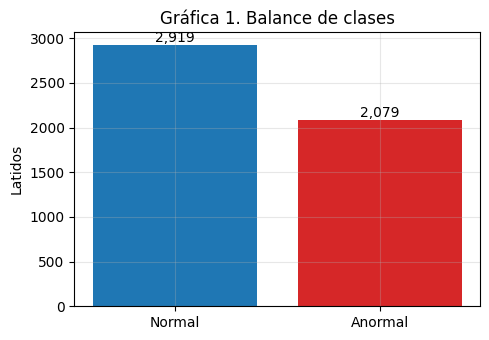

In [3]:
conteo = pd.Series(y).map(NOMBRES_CLASE).value_counts()
balance = pd.DataFrame({"latidos": conteo, "porcentaje": (conteo / len(y) * 100).round(1)})
print(f"Valores faltantes: {int(ecg.isna().sum().sum())}")
print(f"Rango de amplitud en desarrollo: {X_resto.min():.2f} a {X_resto.max():.2f}")
display(balance)

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(balance.index, balance["latidos"], color=[COLORES_CLASE[0] if c == "Normal" else COLORES_CLASE[1] for c in balance.index])
for i, valor in enumerate(balance["latidos"]):
    ax.text(i, valor, f"{valor:,}", ha="center", va="bottom")
ax.set_title("Gráfica 1. Balance de clases")
ax.set_ylabel("Latidos")
plt.tight_layout()
plt.show()

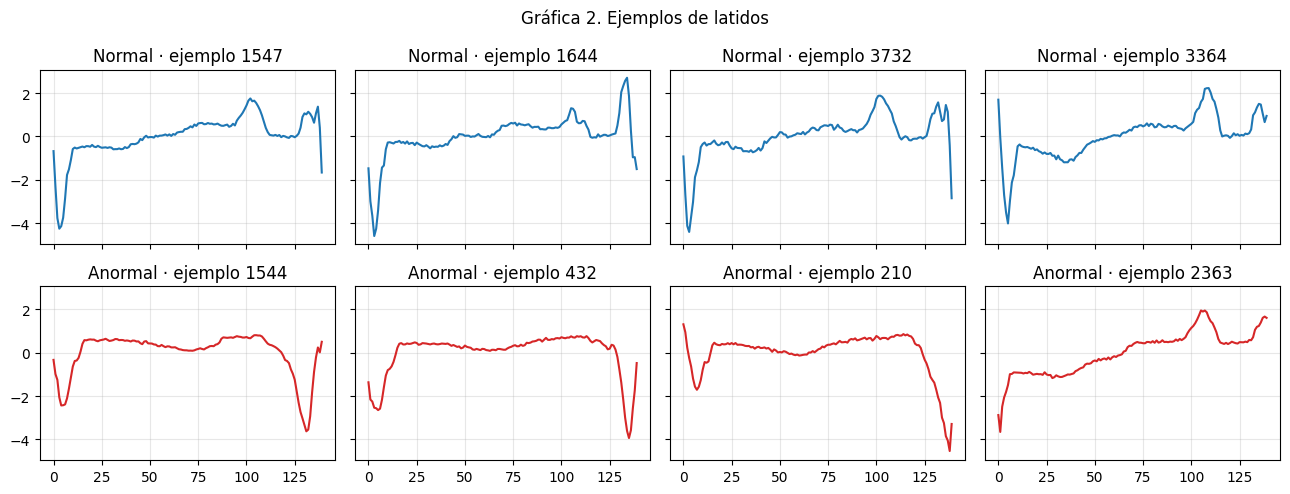

In [4]:
rng = np.random.default_rng(SEED)
fig, ejes = plt.subplots(2, 4, figsize=(13, 5), sharex=True, sharey=True)
for fila, clase in enumerate([0, 1]):
    indices = rng.choice(np.where(y_resto == clase)[0], size=4, replace=False)
    for ax, i in zip(ejes[fila], indices):
        ax.plot(X_resto[i], color=COLORES_CLASE[clase])
        ax.set_title(f"{NOMBRES_CLASE[clase]} · ejemplo {i}")
fig.suptitle("Gráfica 2. Ejemplos de latidos")
plt.tight_layout()
plt.show()

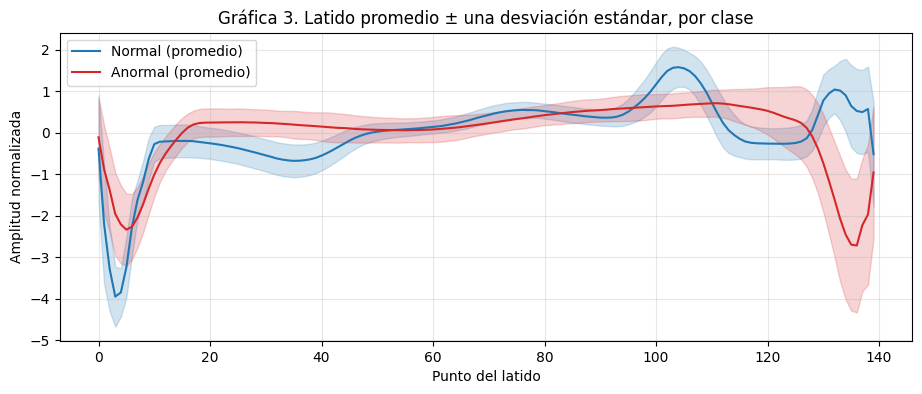

In [5]:
fig, ax = plt.subplots()
puntos = np.arange(X_resto.shape[1])
for clase in [0, 1]:
    grupo = X_resto[y_resto == clase]
    media, desv = grupo.mean(axis=0), grupo.std(axis=0)
    ax.plot(puntos, media, color=COLORES_CLASE[clase], label=f"{NOMBRES_CLASE[clase]} (promedio)")
    ax.fill_between(puntos, media - desv, media + desv, color=COLORES_CLASE[clase], alpha=0.2)
ax.set_title("Gráfica 3. Latido promedio ± una desviación estándar, por clase")
ax.set_xlabel("Punto del latido")
ax.set_ylabel("Amplitud normalizada")
ax.legend()
plt.show()

**En dos líneas, di en qué partes del latido se separan más las dos clases según la gráfica 3 y dónde se enciman.**

R= Las clases se separan drásticamente entre los puntos 95-115 y 130-140, donde las curvas toman direcciones opuestas. Se enciman entre los puntos 50 y 90 aproximadamente, donde las dos curvas casi coinciden.

## 4. Preparación
- **División:** `X_resto` se parte en 80 % entrenamiento y 20 % validación, de forma estratificada.
- **Normalización:** el examen dice que los latidos ya vienen normalizados. La celda lo comprueba latido por latido. Si es así, no se ajusta ningún escalador, de modo que la prueba no puede filtrarse por esa vía.
- **Formato:** las redes reciben cada latido como una serie de 140 pasos con 1 canal.
- **Duplicados:** un latido idéntico en entrenamiento y validación inflaría la validación, así que se quita de entrenamiento.
- **Pesos de clase:** hay más latidos normales que anormales. Con pesos balanceados, calculados solo con entrenamiento, la red no se inclina hacia la clase mayoritaria. El umbral se queda en 0.5, como pide el cliente.

In [6]:
X_train, X_val, y_train, y_val = train_test_split(X_resto, y_resto, test_size=0.2, stratify=y_resto, random_state=SEED)

media_latido = X_resto.mean(axis=1)
desv_latido = X_resto.std(axis=1)
ya_normalizado = np.abs(media_latido).mean() < 0.1 and np.abs(desv_latido - 1).mean() < 0.1
print(f"Por latido: media promedio {media_latido.mean():.3f}, desviación promedio {desv_latido.mean():.3f}")
print("Comprobación:", "ya normalizados, no se reescala" if ya_normalizado else "NO parecen normalizados, revisar antes de seguir")

huellas_val = {latido.tobytes() for latido in X_val}
repetido = np.array([latido.tobytes() in huellas_val for latido in X_train])
print(f"Latidos de entrenamiento idénticos a uno de validación (se quitan): {int(repetido.sum())}")
X_train, y_train = X_train[~repetido], y_train[~repetido]

clases = np.array([0, 1])
pesos = compute_class_weight("balanced", classes=clases, y=y_train)
pesos_clase = {int(c): float(p) for c, p in zip(clases, pesos)}

print(f"Entrenamiento: {len(y_train):,} ({y_train.mean():.1%} anormales)")
print(f"Validación: {len(y_val):,} ({y_val.mean():.1%} anormales)")
print(f"Pesos de clase: {pesos_clase}")

Por latido: media promedio 0.000, desviación promedio 0.996
Comprobación: ya normalizados, no se reescala
Latidos de entrenamiento idénticos a uno de validación (se quitan): 0
Entrenamiento: 3,198 (41.6% anormales)
Validación: 800 (41.6% anormales)
Pesos de clase: {0: 0.8559957173447538, 1: 1.2022556390977444}


### Funciones de medición
Las mismas funciones miden la validación y la prueba, siempre con umbral de 0.5.

In [7]:
def metricas(y_real, prob):
    pred = (prob >= UMBRAL).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_real, pred, labels=[0, 1]).ravel()
    return {"sensibilidad": tp / (tp + fn), "especificidad": tn / (tn + fp), "auc": roc_auc_score(y_real, prob),
            "vp": int(tp), "fn": int(fn), "vn": int(tn), "fp": int(fp)}


def parametros_entrenables(modelo):
    return int(sum(np.prod(peso.shape) for peso in modelo.trainable_weights))


def intervalo_wilson(aciertos, total, z=1.96):
    p = aciertos / total
    centro = (p + z**2 / (2 * total)) / (1 + z**2 / total)
    radio = z * np.sqrt(p * (1 - p) / total + z**2 / (4 * total**2)) / (1 + z**2 / total)
    return centro - radio, centro + radio

## 5. Línea base trivial
`DummyClassifier` responde siempre la clase más frecuente: «todo es normal». Su especificidad es perfecta y su sensibilidad es cero, así que no detecta nada. Sirve para ver que la exactitud sola engañaría, ya que acertaría más de la mitad sin aprender nada.

In [8]:
base = DummyClassifier(strategy="most_frequent")
base.fit(X_train, y_train)

NOMBRE_BASE = "Línea base (todo normal)"
candidatos = {NOMBRE_BASE: {"tipo": "linea base", "parametros": 0, "probabilidad": lambda datos: base.predict_proba(datos)[:, 1]}}
print(metricas(y_val, candidatos[NOMBRE_BASE]["probabilidad"](X_val)))

{'sensibilidad': np.float64(0.0), 'especificidad': np.float64(1.0), 'auc': np.float64(0.5), 'vp': 0, 'fn': 333, 'vn': 467, 'fp': 0}


## 6. Modelos
Tres redes pequeñas, porque el límite de 20,000 parámetros descarta las grandes:

| Modelo | Tipo | Por qué probarlo |
|---|---|---|
| **Conv1D** | convolucional | Busca formas locales del latido, como una onda deformada, sin importar dónde caigan |
| **TCN** | convolucional | Sus convoluciones dilatadas ven casi todo el latido con pocos parámetros: 125 de 140 puntos |
| **Bi-GRU** | recurrente | Lee el latido en orden, en los dos sentidos, y puede captar la relación entre partes alejadas |

No uso MLP: la columna `tipo` que pide el examen no tiene una categoría para él. Tampoco uso BatchNorm, para que los parámetros totales y los entrenables sean el mismo número y no haya duda sobre el límite.

Todas se entrenan igual: Adam con 10⁻³, lotes de 32, pérdida binaria con pesos de clase, y parada temprana con la pérdida de validación.

In [9]:
LARGO = X_train.shape[1]
EPOCAS = 150
PACIENCIA = 15


def crear_conv1d():
    return keras.Sequential([
        keras.Input(shape=(LARGO, 1)),
        layers.Conv1D(16, 7, padding="same", activation="relu"),
        layers.MaxPooling1D(2),
        layers.Conv1D(32, 5, padding="same", activation="relu"),
        layers.MaxPooling1D(2),
        layers.Conv1D(32, 3, padding="same", activation="relu"),
        layers.GlobalAveragePooling1D(),
        layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid"),
    ], name="conv1d")


def crear_tcn(filtros=24, nucleo=5, dilataciones=(1, 2, 4, 8, 16)):
    entradas = keras.Input(shape=(LARGO, 1))
    x = layers.Conv1D(filtros, 1)(entradas)
    for dilatacion in dilataciones:
        residuo = layers.Conv1D(filtros, nucleo, padding="causal", dilation_rate=dilatacion, activation="relu")(x)
        residuo = layers.SpatialDropout1D(0.1)(residuo)
        x = layers.Add()([x, residuo])
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(0.3)(x)
    salidas = layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(entradas, salidas, name="tcn")


def crear_bigru():
    return keras.Sequential([
        keras.Input(shape=(LARGO, 1)),
        layers.Bidirectional(layers.GRU(32)),
        layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid"),
    ], name="bigru")


def entrenar(nombre, tipo, crear):
    keras.utils.set_random_seed(SEED)
    modelo = crear()
    total = modelo.count_params()
    assert total <= MAX_PARAMETROS, f"{nombre} tiene {total:,} parámetros y el límite es {MAX_PARAMETROS:,}"
    modelo.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=[keras.metrics.AUC(name="auc")])
    parada = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PACIENCIA, restore_best_weights=True)
    historia = modelo.fit(X_train[..., None], y_train, validation_data=(X_val[..., None], y_val), epochs=EPOCAS,
                          batch_size=32, class_weight=pesos_clase, callbacks=[parada], verbose=0)
    candidatos[nombre] = {"tipo": tipo, "parametros": parametros_entrenables(modelo), "modelo": modelo, "historia": historia,
                          "probabilidad": lambda datos, red=modelo: red.predict(datos[..., None], verbose=0).ravel()}
    print(f"{nombre}: {candidatos[nombre]['parametros']:,} parámetros · {len(historia.history['loss'])} épocas")


entrenar("Conv1D", "convolucional", crear_conv1d)
entrenar("TCN", "convolucional", crear_tcn)
entrenar("Bi-GRU", "recurrente", crear_bigru)

Conv1D: 5,857 parámetros · 118 épocas
TCN: 14,593 parámetros · 82 épocas
Bi-GRU: 6,785 parámetros · 53 épocas


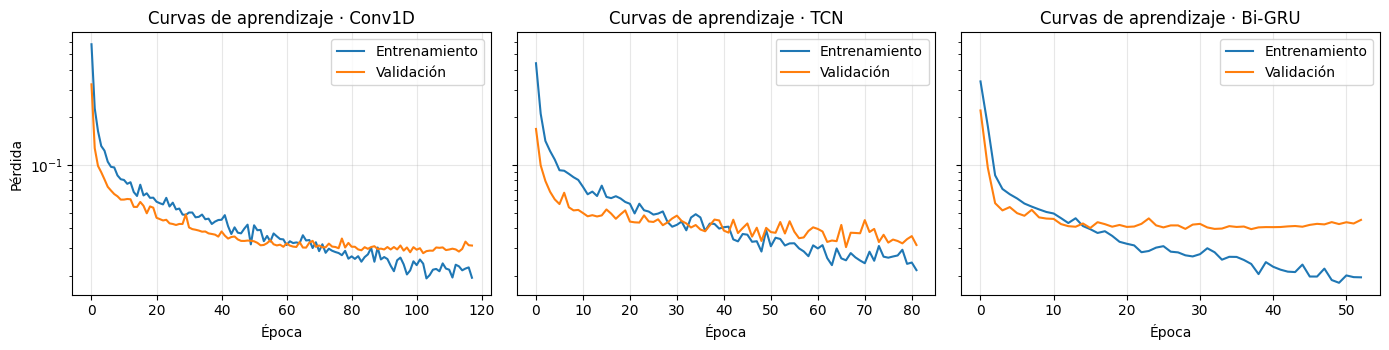

In [10]:
redes = [nombre for nombre, datos in candidatos.items() if "historia" in datos]
fig, ejes = plt.subplots(1, len(redes), figsize=(14, 3.6), sharey=True)
for ax, nombre in zip(ejes, redes):
    historia = candidatos[nombre]["historia"].history
    ax.plot(historia["loss"], label="Entrenamiento")
    ax.plot(historia["val_loss"], label="Validación")
    ax.set_title(f"Curvas de aprendizaje · {nombre}")
    ax.set_xlabel("Época")
    ax.set_yscale("log")
    ax.legend()
ejes[0].set_ylabel("Pérdida")
plt.tight_layout()
plt.show()

## 7. Elección con validación
**Regla, fijada antes de ver los resultados:**

1. Se usa siempre el umbral de 0.5.
2. Entre las redes que cumplen 95 % de sensibilidad y 95 % de especificidad en validación, gana la de mayor margen: el valor más bajo de sus dos métricas.
3. Si hay empate en ese margen, redondeado a tres decimales, gana la de menos parámetros, porque cabe mejor en el monitor.
4. Si ninguna cumple, se elige la de mayor margen y se reporta que no alcanzó.

In [11]:
filas_val = []
for nombre, datos in candidatos.items():
    m = metricas(y_val, datos["probabilidad"](X_val))
    filas_val.append({"modelo": nombre, "tipo": datos["tipo"], "parametros": datos["parametros"], "sensibilidad": m["sensibilidad"],
                      "especificidad": m["especificidad"], "auc": m["auc"], "falsos_negativos": m["fn"], "falsos_positivos": m["fp"]})
tabla_val = pd.DataFrame(filas_val)
tabla_val["margen"] = tabla_val[["sensibilidad", "especificidad"]].min(axis=1).round(3)
tabla_val["cumple_val"] = (tabla_val["sensibilidad"] >= MIN_SENSIBILIDAD) & (tabla_val["especificidad"] >= MIN_ESPECIFICIDAD)
display(tabla_val.round(4))

solo_redes = tabla_val[tabla_val["modelo"] != NOMBRE_BASE]
grupo = solo_redes[solo_redes["cumple_val"]] if solo_redes["cumple_val"].any() else solo_redes
nombre_elegido = grupo.sort_values(["margen", "parametros"], ascending=[False, True]).iloc[0]["modelo"]
fila = tabla_val.set_index("modelo").loc[nombre_elegido]

aviso = "cumple las dos especificaciones en validación" if fila["cumple_val"] else "**no** cumple las dos especificaciones en validación; es la de mayor margen"
display(Markdown(f"**Modelo elegido: {nombre_elegido}.** En validación tiene {fila['sensibilidad']:.1%} de sensibilidad, "
                 f"{fila['especificidad']:.1%} de especificidad y {fila['parametros']:,} parámetros; {aviso}. Esta elección ya no cambia."))

,modelo,tipo,parametros,sensibilidad,especificidad,auc,falsos_negativos,falsos_positivos,margen,cumple_val
0,Línea base (todo normal),linea base,0,0.000,1.0000,0.5000,333,0,0.000,False
1,Conv1D,convolucional,5857,0.994,0.9957,0.9976,2,2,0.994,True
2,TCN,convolucional,14593,0.991,0.9914,0.9980,3,4,0.991,True
3,Bi-GRU,recurrente,6785,0.991,0.9914,0.9969,3,4,0.991,True


**Modelo elegido: Conv1D.** En validación tiene 99.4% de sensibilidad, 99.6% de especificidad y 5,857 parámetros; cumple las dos especificaciones en validación. Esta elección ya no cambia.

## 8. Prueba del cliente, una sola vez
Se miden todos los modelos para llenar `resultados`, pero la elección de arriba no cambia. El candado de la primera línea evita repetir la medición sin darse cuenta.

`cumple` exige las dos métricas y el límite de parámetros.

In [12]:
assert "resultados" not in globals(), "La prueba ya se usó en esta sesión: su resultado no se debe volver a buscar."

metricas_prueba = {}
probs_prueba = {}
filas = []
for nombre, datos in candidatos.items():
    probs_prueba[nombre] = datos["probabilidad"](X_prueba)
    m = metricas(y_prueba, probs_prueba[nombre])
    metricas_prueba[nombre] = m
    cumple = bool(m["sensibilidad"] >= MIN_SENSIBILIDAD and m["especificidad"] >= MIN_ESPECIFICIDAD
                  and datos["parametros"] <= MAX_PARAMETROS)
    filas.append({"modelo": nombre, "tipo": datos["tipo"], "parametros": datos["parametros"], "sensibilidad": m["sensibilidad"],
                  "especificidad": m["especificidad"], "auc": m["auc"], "cumple": cumple, "elegido": nombre == nombre_elegido})

resultados = pd.DataFrame(filas)
resultados.to_csv("resultados_ecg.csv", index=False)
resultados

,modelo,tipo,parametros,sensibilidad,especificidad,auc,cumple,elegido
0,Línea base (todo normal),linea base,0,0.000000,1.000000,0.500000,False,False
1,Conv1D,convolucional,5857,0.992788,0.994863,0.998617,True,True
2,TCN,convolucional,14593,0.987981,0.994863,0.999004,True,False
3,Bi-GRU,recurrente,6785,0.990385,0.998288,0.998819,True,False


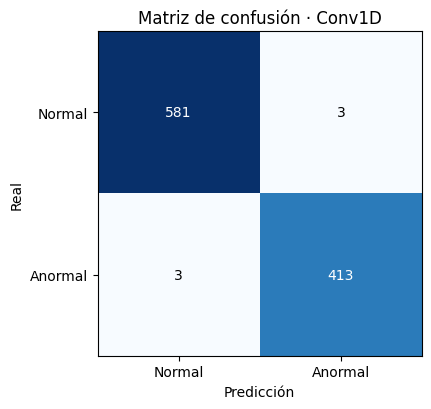


**En palabras del cliente, con Conv1D:**

- De cada 100 latidos anormales, marca 99. Dejó pasar 3 de 416. Intervalo al 95 %: 97.9% a 99.8%.
- De cada 100 latidos normales, marca como anormales 1. Fueron 3 de 584. Intervalo al 95 %: 98.5% a 99.8%.
- Tamaño: 5,857 parámetros, de un máximo de 20,000.
- Latidos de prueba idénticos a alguno de desarrollo: 0.

**Sí cumple** todas las especificaciones.


In [13]:
m = metricas_prueba[nombre_elegido]
anormales, normales = m["vp"] + m["fn"], m["vn"] + m["fp"]
ic_sens = intervalo_wilson(m["vp"], anormales)
ic_esp = intervalo_wilson(m["vn"], normales)
cumple_elegido = bool(resultados.loc[resultados["elegido"], "cumple"].iloc[0])

huellas_desarrollo = {latido.tobytes() for latido in X_resto}
repetidos_prueba = sum(latido.tobytes() in huellas_desarrollo for latido in X_prueba)

matriz = np.array([[m["vn"], m["fp"]], [m["fn"], m["vp"]]])
fig, ax = plt.subplots(figsize=(4.8, 4.2))
ax.imshow(matriz, cmap="Blues")
ax.set_xticks([0, 1], ["Normal", "Anormal"])
ax.set_yticks([0, 1], ["Normal", "Anormal"])
for i in range(2):
    for j in range(2):
        ax.text(j, i, matriz[i, j], ha="center", va="center", color="white" if matriz[i, j] > matriz.max() / 2 else "black")
ax.set_xlabel("Predicción")
ax.set_ylabel("Real")
ax.set_title(f"Matriz de confusión · {nombre_elegido}")
ax.grid(False)
plt.tight_layout()
plt.show()

veredicto = "**Sí cumple** todas las especificaciones." if cumple_elegido else ("**No cumple** todas las especificaciones. No se reajusta: "
            "se reconoce en el folleto y se explica qué haría falta para lograrlo.")
display(Markdown(f'''
**En palabras del cliente, con {nombre_elegido}:**

- De cada 100 latidos anormales, marca {m['sensibilidad'] * 100:.0f}. Dejó pasar {m['fn']} de {anormales}. Intervalo al 95 %: {ic_sens[0]:.1%} a {ic_sens[1]:.1%}.
- De cada 100 latidos normales, marca como anormales {(1 - m['especificidad']) * 100:.0f}. Fueron {m['fp']} de {normales}. Intervalo al 95 %: {ic_esp[0]:.1%} a {ic_esp[1]:.1%}.
- Tamaño: {candidatos[nombre_elegido]['parametros']:,} parámetros, de un máximo de {MAX_PARAMETROS:,}.
- Latidos de prueba idénticos a alguno de desarrollo: {repetidos_prueba}.

{veredicto}
'''))

### Justificación de la elección
**Elegimos Conv1D.** La regla se fijó antes de ver los resultados, y la elección se hizo solo con validación:

| Modelo | Sensibilidad | Especificidad | Margen | AUC | Parámetros |
|---|---|---|---|---|---|
| **Conv1D** | **99.4 %** | **99.6 %** | **0.994** | 0.9976 | **5,857** |
| TCN | 99.1 % | 99.1 % | 0.991 | 0.9980 | 14,593 |
| Bi-GRU | 99.1 % | 99.1 % | 0.991 | 0.9969 | 6,785 |

- **Cumple y tiene el mayor margen.** Las tres redes pasan 95/95 en validación, y Conv1D tiene el valor más alto en su métrica más baja: se equivocó en 2 anormales y 2 normales de 800 latidos, contra 3 y 4 de las otras dos.
- **Es la más pequeña.** Usa 29 % del límite de 20,000 parámetros y pesa 108 KB. La TCN necesita 2.5 veces más parámetros sin ser mejor en las métricas del cliente.
- **Sus curvas son las más sanas.** Entrenamiento y validación bajan juntas durante casi todo el entrenamiento, mientras que en Bi-GRU la pérdida de validación se estanca cerca de la época 10 y la de entrenamiento sigue bajando.

**Con honestidad:** la diferencia entre las tres es de 1 o 2 latidos en cada métrica, demasiado poco para decir que Conv1D es superior. Lo que inclina la decisión es que da el mismo desempeño práctico con el modelo más pequeño. La TCN tiene un AUC de validación apenas mayor, pero el cliente fija el umbral en 0.5, así que el AUC no entró en la regla.

La prueba no participó en esta decisión. Ahí las tres redes también cumplen, y Conv1D confirma la validación con 99.3 % de sensibilidad y 99.5 % de especificidad.

## 9. Análisis de 3 errores
Tomo los errores más seguros del modelo elegido: dos falsos negativos, que son los que más le importan al cardiólogo, y un falso positivo. Si no hay suficientes de un tipo, completo con el otro.

Cada latido se compara con los promedios de entrenamiento. `distancia_normal` y `distancia_anormal` indican a cuál se parece más su forma.

,indice_prueba,real,prediccion,tipo_error,prob_anormal,distancia_normal,distancia_anormal
0,135,Anormal,Normal,falso negativo,0.001,0.349,0.903
1,160,Anormal,Normal,falso negativo,0.002,0.608,0.973
2,75,Normal,Anormal,falso positivo,0.915,0.674,0.731


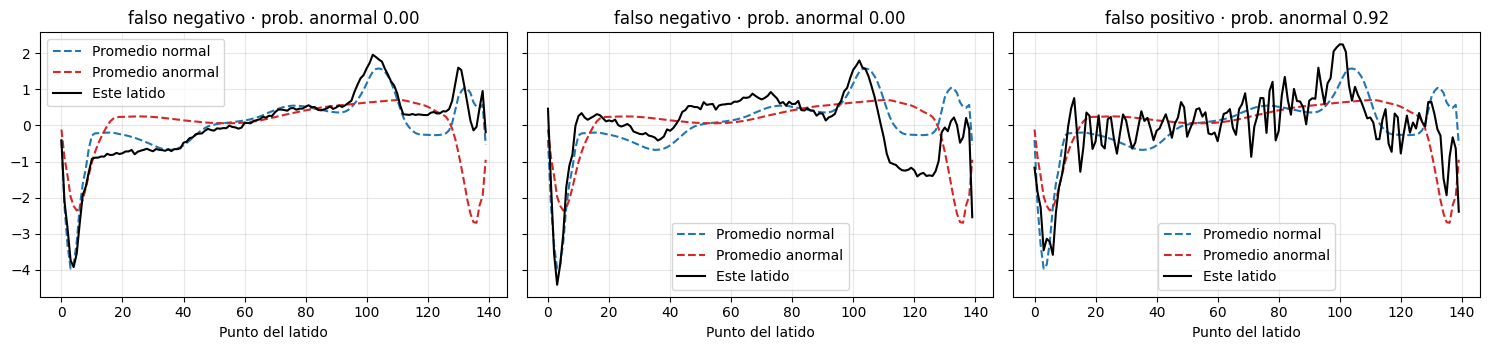

In [14]:
prob_elegido = probs_prueba[nombre_elegido]
pred_elegido = (prob_elegido >= UMBRAL).astype(int)
falsos_neg = np.where((y_prueba == 1) & (pred_elegido == 0))[0]
falsos_pos = np.where((y_prueba == 0) & (pred_elegido == 1))[0]
falsos_neg = falsos_neg[np.argsort(prob_elegido[falsos_neg])]
falsos_pos = falsos_pos[np.argsort(-prob_elegido[falsos_pos])]

errores = list(falsos_neg[:2]) + list(falsos_pos[:1])
sobrantes = list(falsos_neg[2:]) + list(falsos_pos[1:])
errores += sobrantes[:3 - len(errores)]

promedio_normal = X_train[y_train == 0].mean(axis=0)
promedio_anormal = X_train[y_train == 1].mean(axis=0)


def distancia(a, b):
    return float(np.sqrt(np.mean((a - b) ** 2)))


filas_error = []
for i in errores:
    filas_error.append({"indice_prueba": int(i), "real": NOMBRES_CLASE[int(y_prueba[i])], "prediccion": NOMBRES_CLASE[int(pred_elegido[i])],
                        "tipo_error": "falso negativo" if y_prueba[i] == 1 else "falso positivo", "prob_anormal": prob_elegido[i],
                        "distancia_normal": distancia(X_prueba[i], promedio_normal),
                        "distancia_anormal": distancia(X_prueba[i], promedio_anormal)})
tabla_errores = pd.DataFrame(filas_error)
display(tabla_errores.round(3))

if errores:
    fig, ejes = plt.subplots(1, len(errores), figsize=(5 * len(errores), 3.6), sharey=True, squeeze=False)
    for ax, i, fila_error in zip(ejes[0], errores, filas_error):
        ax.plot(promedio_normal, color=COLORES_CLASE[0], linestyle="--", label="Promedio normal")
        ax.plot(promedio_anormal, color=COLORES_CLASE[1], linestyle="--", label="Promedio anormal")
        ax.plot(X_prueba[i], color="black", label="Este latido")
        ax.set_title(f"{fila_error['tipo_error']} · prob. anormal {fila_error['prob_anormal']:.2f}")
        ax.set_xlabel("Punto del latido")
        ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print("El modelo no cometió errores en la prueba: revisa que eso sea creíble antes de presumirlo.")

Los tres errores salen de los 6 que cometió el modelo en 1,000 latidos de prueba: 3 falsos negativos y 3 falsos positivos.

1. **Error 1, latido 135: falso negativo con probabilidad de 0.001.** Tiene la forma de un latido normal: la caída profunda al inicio (cerca de −4), el pico cerca del punto 100 y el rebote positivo cerca del 130. Su distancia al promedio normal (0.349) es menos de la mitad de la distancia al anormal (0.903). Justo las zonas que más separan a las clases, según la gráfica 3, se parecen a las normales. La diferencia está sobre todo entre los puntos 15 y 40, donde queda más bajo que el promedio normal, y es sutil. **Consecuencia:** es el peor tipo de error, porque el cardiólogo nunca vería este latido.

2. **Error 2, latido 160: falso negativo con probabilidad de 0.002.** Es un latido híbrido. Conserva la caída inicial y el pico cerca del punto 100, ambos típicos de un latido normal, pero entre los puntos 110 y 128 baja hasta cerca de −1.4, y le falta el rebote positivo cerca del 130. Tampoco tiene la caída profunda del promedio anormal en esa zona. Quedó más cerca del promedio normal (0.608 contra 0.973), y el modelo pesó más lo normal. **Consecuencia:** es otro latido anormal que no llega a revisión, a pesar de tener una forma visiblemente rara.

3. **Error 3, latido 75: falso positivo con probabilidad de 0.915.** Es el único de los tres con la señal muy ruidosa: oscila en todo el latido. Además, baja cerca de −2 hacia el final y no tiene el rebote positivo del punto 130, y eso se parece al patrón anormal. Queda casi a la misma distancia de los dos promedios (0.674 y 0.731). Las oscilaciones podrían ser ruido de la medición, pero con estos datos no podemos confirmarlo. **Consecuencia:** es un error menor, porque el cardiólogo revisa un latido de más y lo descarta.

**Lo que enseñan juntos:** los dos falsos negativos tienen probabilidades casi de cero, así que el modelo se equivoca muy seguro de sí mismo. Bajar el umbral un poco no los recuperaría, y una probabilidad baja no garantiza que el latido esté sano. Además, el ruido puede provocar marcas falsas. Por eso conviene probarlo con señales reales del monitor, que pueden tener más ruido.

## 10. Con qué pacientes funcionaría
El cliente pidió saberlo con honestidad, y estos límites son los que van al folleto.

- **Un solo paciente.** Todos los latidos, también los de prueba, vienen del Holter de una persona con insuficiencia cardiaca. El resultado dice que el modelo reconoce los latidos de esa persona. **No hay evidencia de que funcione con otros pacientes**, con otras enfermedades, ni con edades, electrodos o monitores distintos.
- **Latidos vecinos.** La división es aleatoria, así que la prueba tiene latidos del mismo registro que los de entrenamiento. Es una prueba más fácil que un paciente nuevo.
- **Latidos ya preparados.** Aquí cada latido llega recortado a 140 puntos y normalizado. El monitor tendría que detectar y recortar cada latido por su cuenta, y ese paso no se probó.
- **Dos clases nada más.** «Anormal» junta varios tipos de latido. El modelo no dice cuál es, y el diagnóstico sigue siendo del cardiólogo.
- **Prevalencia.** Los datos tienen muchos más latidos anormales de lo esperable en un registro común. La tabla de abajo muestra qué pasa con otras proporciones, que son escenarios hipotéticos y no mediciones.

In [15]:
m = metricas_prueba[nombre_elegido]
LATIDOS = 100_000
filas_prevalencia = []
for prevalencia in [0.01, 0.05, 0.20, float(y.mean())]:
    anormales_reg = LATIDOS * prevalencia
    normales_reg = LATIDOS - anormales_reg
    detectados = anormales_reg * m["sensibilidad"]
    falsas_alarmas = normales_reg * (1 - m["especificidad"])
    a_revisar = detectados + falsas_alarmas
    filas_prevalencia.append({"% anormales en el registro": round(prevalencia * 100, 1), "latidos anormales": round(anormales_reg),
                              "detectados": round(detectados), "perdidos": round(anormales_reg - detectados),
                              "falsas alarmas": round(falsas_alarmas), "latidos a revisar": round(a_revisar),
                              "% del registro a revisar": round(a_revisar / LATIDOS * 100, 1),
                              "de cada 100 marcas, son anormales": round(detectados / a_revisar * 100, 1)})
tabla_prevalencia = pd.DataFrame(filas_prevalencia)
display(Markdown(f"**Registro hipotético de {LATIDOS:,} latidos**, con la sensibilidad y la especificidad de prueba de {nombre_elegido}:"))
tabla_prevalencia

**Registro hipotético de 100,000 latidos**, con la sensibilidad y la especificidad de prueba de Conv1D:

,% anormales en el registro,latidos anormales,detectados,perdidos,falsas alarmas,latidos a revisar,% del registro a revisar,"de cada 100 marcas, son anormales"
0,1.0,1000,993,7,509,1501,1.5,66.1
1,5.0,5000,4964,36,488,5452,5.5,91.0
2,20.0,20000,19856,144,411,20267,20.3,98.0
3,41.6,41597,41297,300,300,41597,41.6,99.3


**Cifra para el folleto:** en un registro hipotético de 100,000 latidos con 1 % de anormales, el cardiólogo revisaría 1,501 latidos (1.5 % del registro). De esos, 993 serían anormales reales y 509 falsas alarmas: 66 de cada 100 marcas serían correctas. Se perderían unos 7 latidos anormales. Es un cálculo con las métricas de este único paciente, no una medición con otros pacientes.

**Nota sobre el redondeo:** la salida del paso 8 dice que «marca como anormales 1» de cada 100 normales porque redondea 0.51 %. El dato exacto son 3 de 584, es decir, unos 5 de cada 1,000.

**Aviso ético:** es una herramienta de apoyo para priorizar la revisión, no un diagnóstico. Un latido no marcado no significa que esté sano, y antes de usarla con pacientes haría falta validarla con muchas personas distintas y bajo la regulación de dispositivos médicos.

**Propuesta de mejora:** entrenar y validar con muchos pacientes, por ejemplo con MIT-BIH, dejando pacientes completos fuera de la prueba.

## 11. Guardado del modelo
Se guarda el modelo elegido en `modelo/`, se recarga para comprobar que da las mismas probabilidades, y se empaquetan los archivos para descargarlos.

El cuaderno se descarga aparte, **con sus salidas**: Archivo → Descargar → Descargar .ipynb. Guárdalo como `DEV_ecg.ipynb`.

In [16]:
os.makedirs("modelo", exist_ok=True)
RUTA_MODELO = os.path.join("modelo", "modelo_ecg.keras")
modelo_final = candidatos[nombre_elegido]["modelo"]
modelo_final.save(RUTA_MODELO)

recargado = keras.models.load_model(RUTA_MODELO)
muestra = X_val[:32][..., None]
iguales = np.allclose(modelo_final.predict(muestra, verbose=0), recargado.predict(muestra, verbose=0), atol=1e-5)
print(f"Guardado en {RUTA_MODELO}: {os.path.getsize(RUTA_MODELO) / 1024:.0f} KB")
print(f"La recarga da las mismas probabilidades: {iguales}")
assert iguales

os.makedirs("entrega_ecg", exist_ok=True)
shutil.copy("resultados_ecg.csv", "entrega_ecg/")
shutil.copytree("modelo", "entrega_ecg/modelo", dirs_exist_ok=True)
paquete = shutil.make_archive("entrega_ecg", "zip", "entrega_ecg")
print(f"Paquete listo: {paquete}")

try:
    from google.colab import files
    files.download(paquete)
except ImportError:
    print("Fuera de Colab: toma el .zip de la carpeta actual.")

Guardado en modelo/modelo_ecg.keras: 108 KB
La recarga da las mismas probabilidades: True
Paquete listo: /content/entrega_ecg.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>